# Leakage-free preprocessing and evaluation: Rwanda malaria risk (DHS MIS 2023)
Run top to bottom from the `notebooks/` folder. All statistics and transformers are fit on the training split only.

In [1]:
import sys, warnings, json
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
from IPython.display import Image, display
from src import data as D
from src.pipeline_builder import split_train_test, make_preprocessor_for
from src.diagnostics import run_diagnostics
from src.evaluation import run_evaluation
import os; os.chdir('..')

## 1. Load data and verify the initial N x P

In [2]:
r = D.load_mis2023('data/raw/mis2023'); data, F = r['data'], r['feature_columns']
N0, P0 = len(data), len(F)
print('Initial N x P =', N0, 'x', P0, '| overall positives:', int(data.y.sum()), f'({data.y.mean()*100:.2f}%)')

Initial N x P = 18672 x 53 | overall positives: 179 (0.96%)


## 2. Cluster-grouped, label-stratified split (no cluster appears in both sets)

In [3]:
train, test = split_train_test(data)
print('seed', train.attrs.get('split_seed'), '| train', train.shape, int(train.y.sum()), '| test', test.shape, int(test.y.sum()))
print('cluster overlap:', len(set(train.cluster) & set(test.cluster)))
assert not set(train.cluster) & set(test.cluster)

seed 51 | train (14940, 56) 143 | test (3732, 56) 36
cluster overlap: 0


## 3. Fit preprocessing on X_train only, apply to X_test

In [4]:
prep, groups, num = make_preprocessor_for(train[F], F)
Ztr = prep.fit_transform(train[F]); Zte = prep.transform(test[F])
print('Final N x P (train):', Ztr.shape, '| (test):', Zte.shape)
print('NaNs train/test:', int(Ztr.isna().sum().sum()), int(Zte.isna().sum().sum()))
print('Initial', (N0, P0), '-> final train+test rows', len(Ztr)+len(Zte), 'x', Ztr.shape[1])
assert list(Ztr.columns) == list(Zte.columns)
print({k: len(v) for k, v in groups.items() if isinstance(v, list)})

Final N x P (train): (14940, 95) | (test): (3732, 95)
NaNs train/test: 0 0
Initial (18672, 53) -> final train+test rows 18672 x 95
{'right_skewed': 13, 'other_skewed': 5, 'gaussian': 12}


## 4. Diagnostics and the eight figures (training data only)

In [5]:
stats = run_diagnostics(train, F, figures_dir='figures', stats_path='reports/diagnostic_stats.json', test=test)
print('Little MCAR:', stats['littles_mcar'])
print('Cramer V (hml4 missing):', stats['cramers_v_missing_hml4'])
print('PCA k90/k95:', stats['pca']['k90'], stats['pca']['k95'])
print('pairs |r|>=0.85:', len(stats['collinear_pairs_r_ge_0.85']))

Little MCAR: {'chi2': 6984.318998974315, 'df': 29, 'p_value': 0.0, 'n_patterns': 2}
Cramer V (hml4 missing): {'hml12': 1.0, 'hv024': 0.356, 'hv025': 0.057, 'hv270': 0.166, 'hv227': 0.696, 'hv104': 0.042}
PCA k90/k95: 12 15
pairs |r|>=0.85: 20


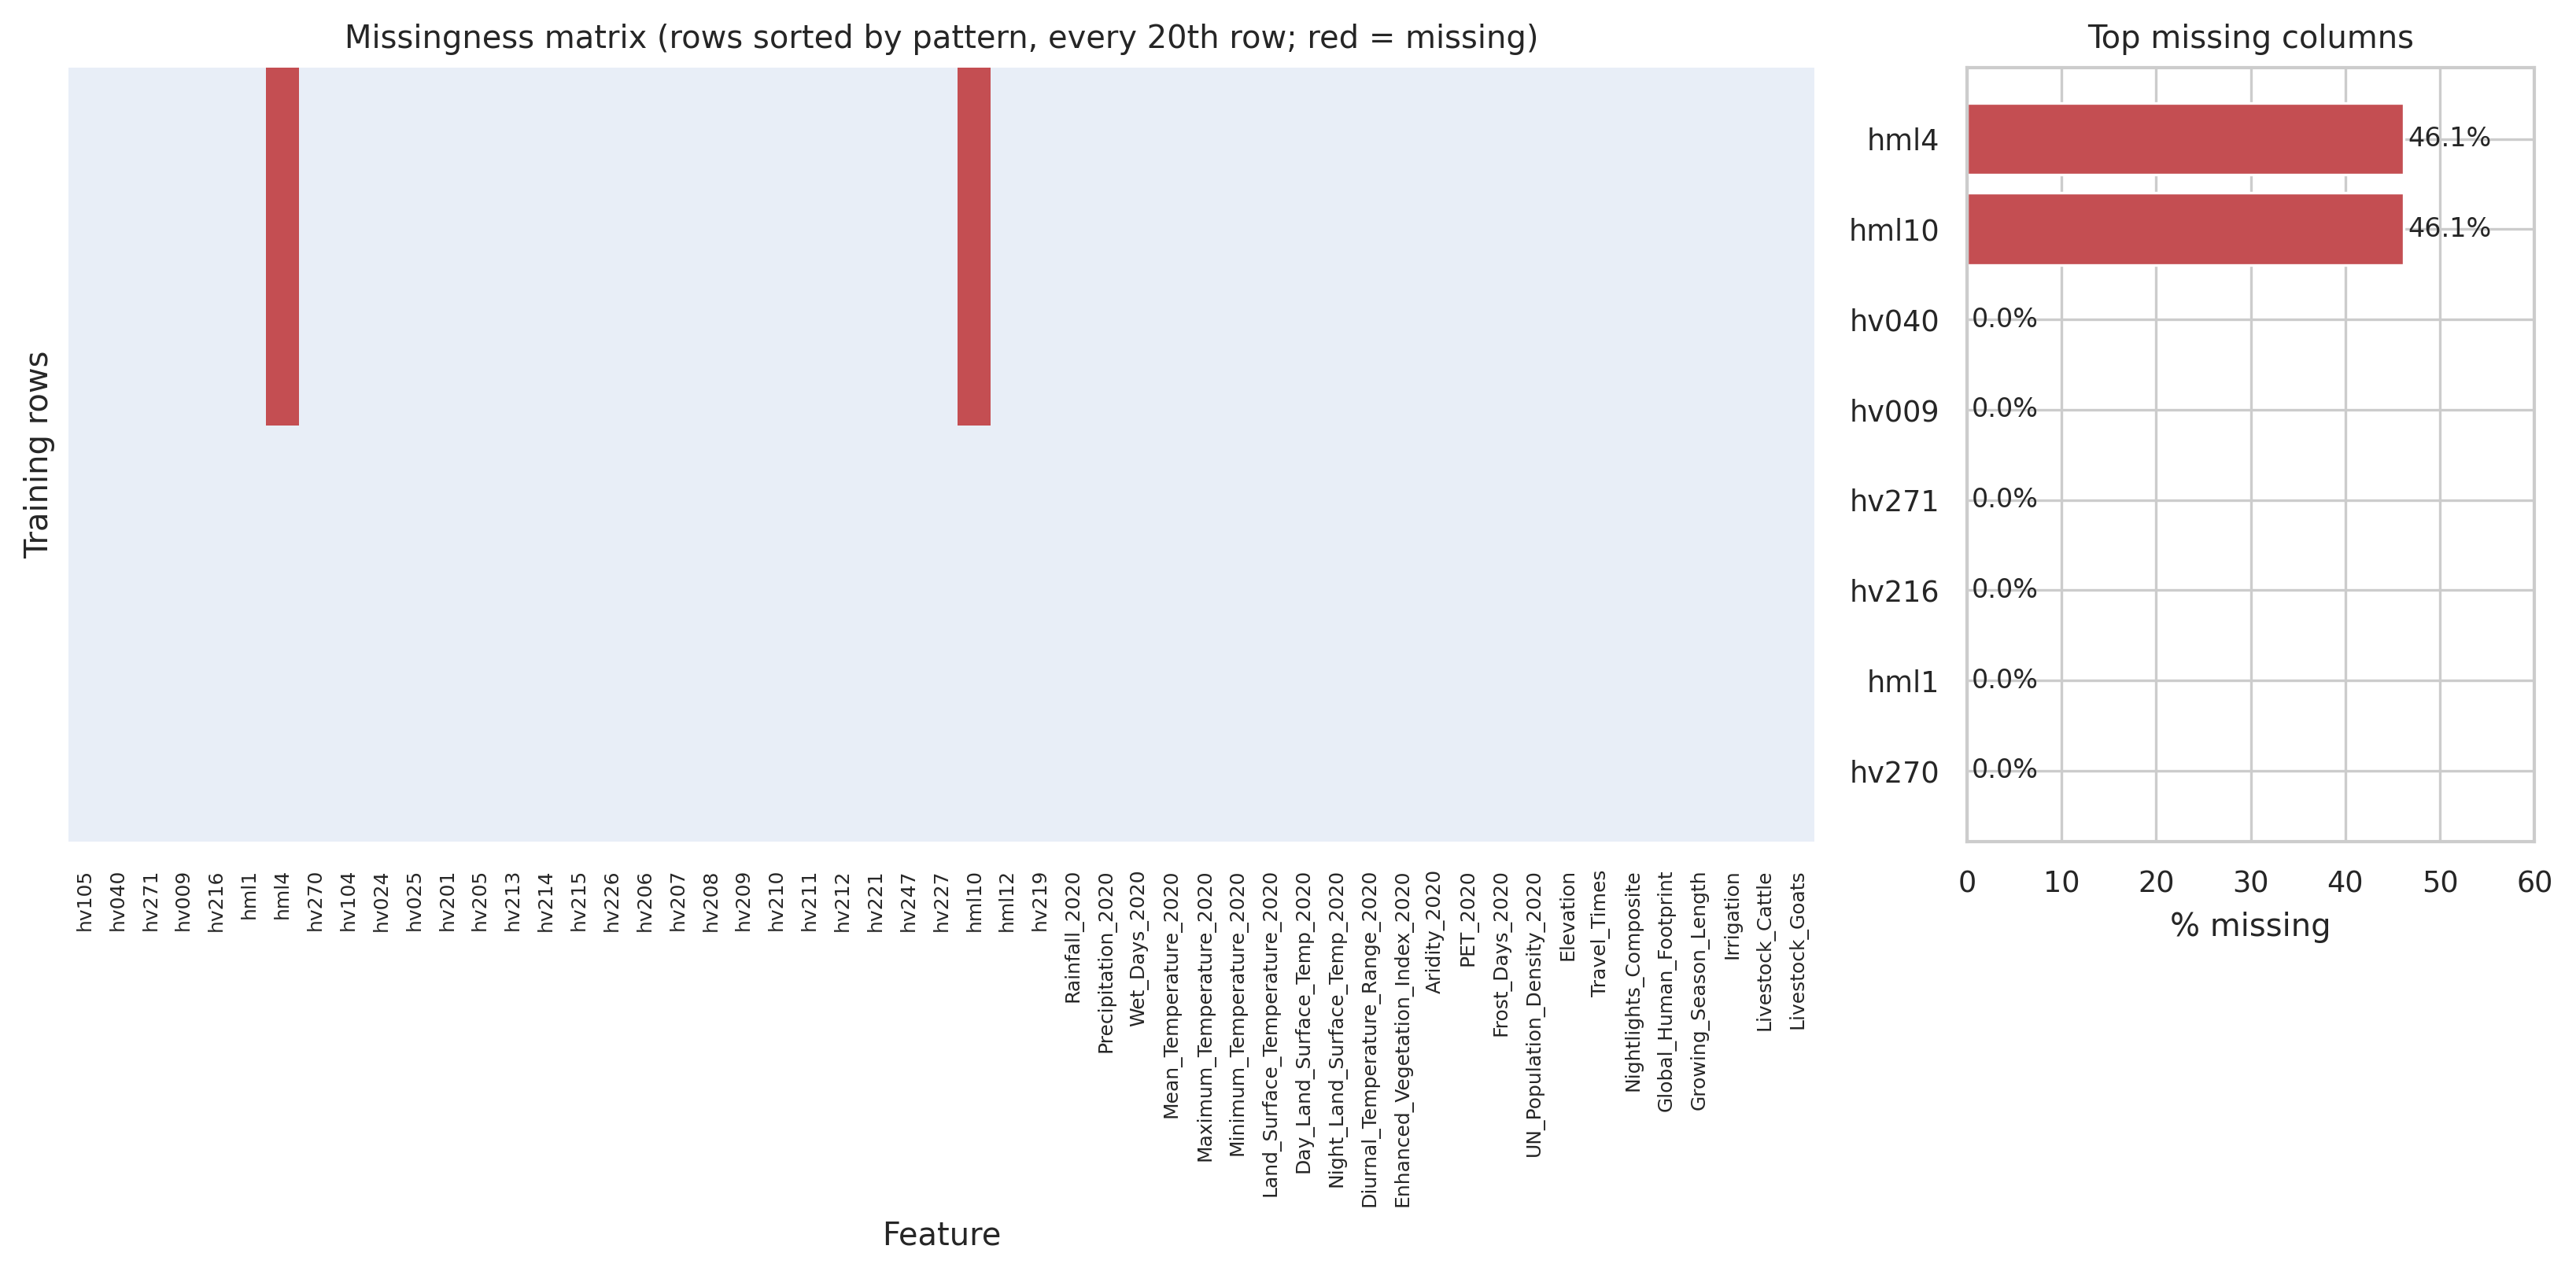

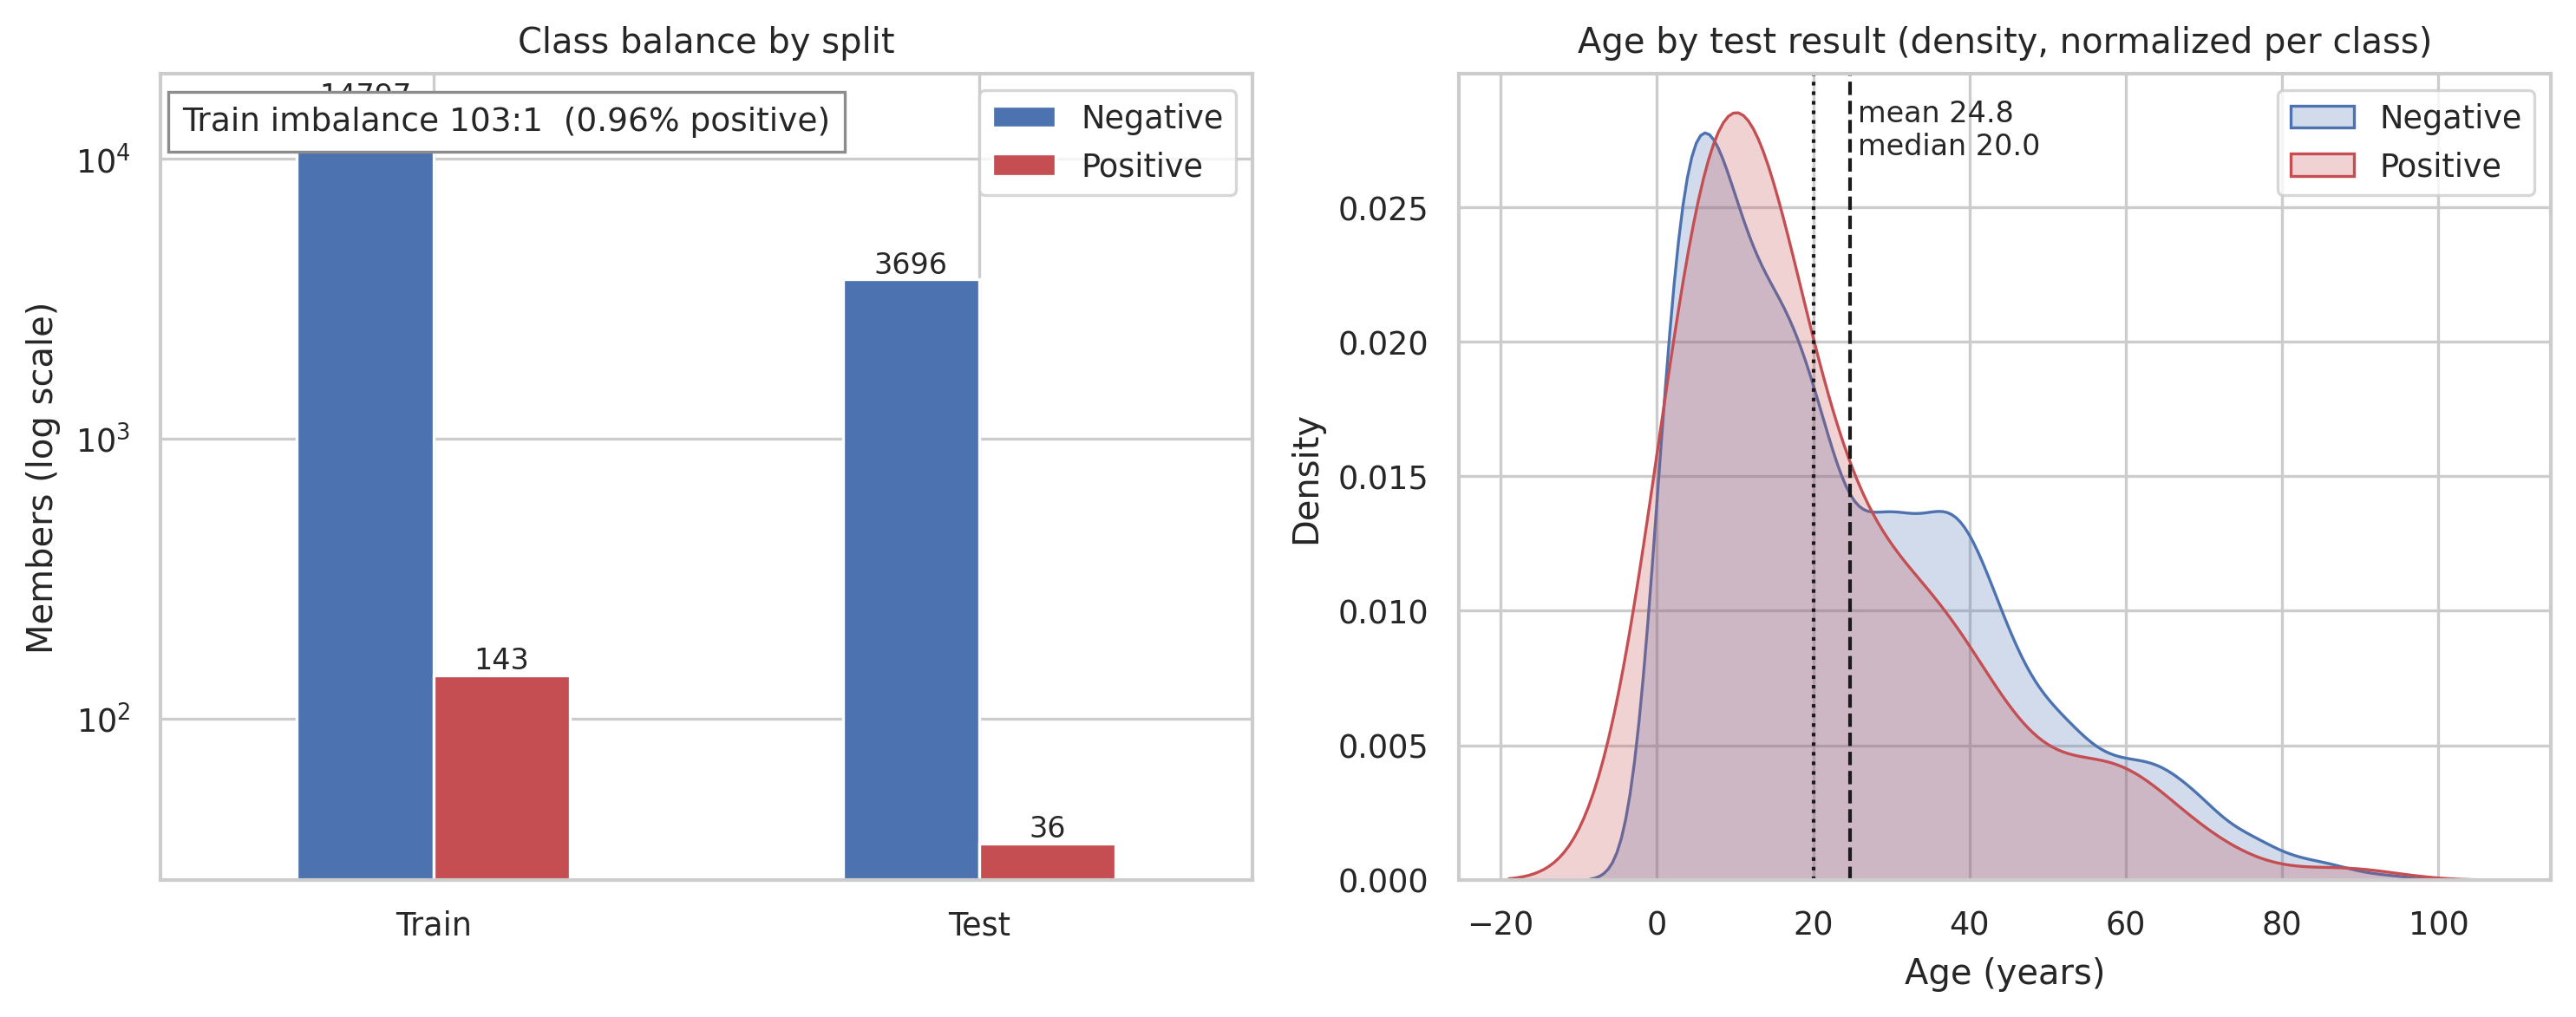

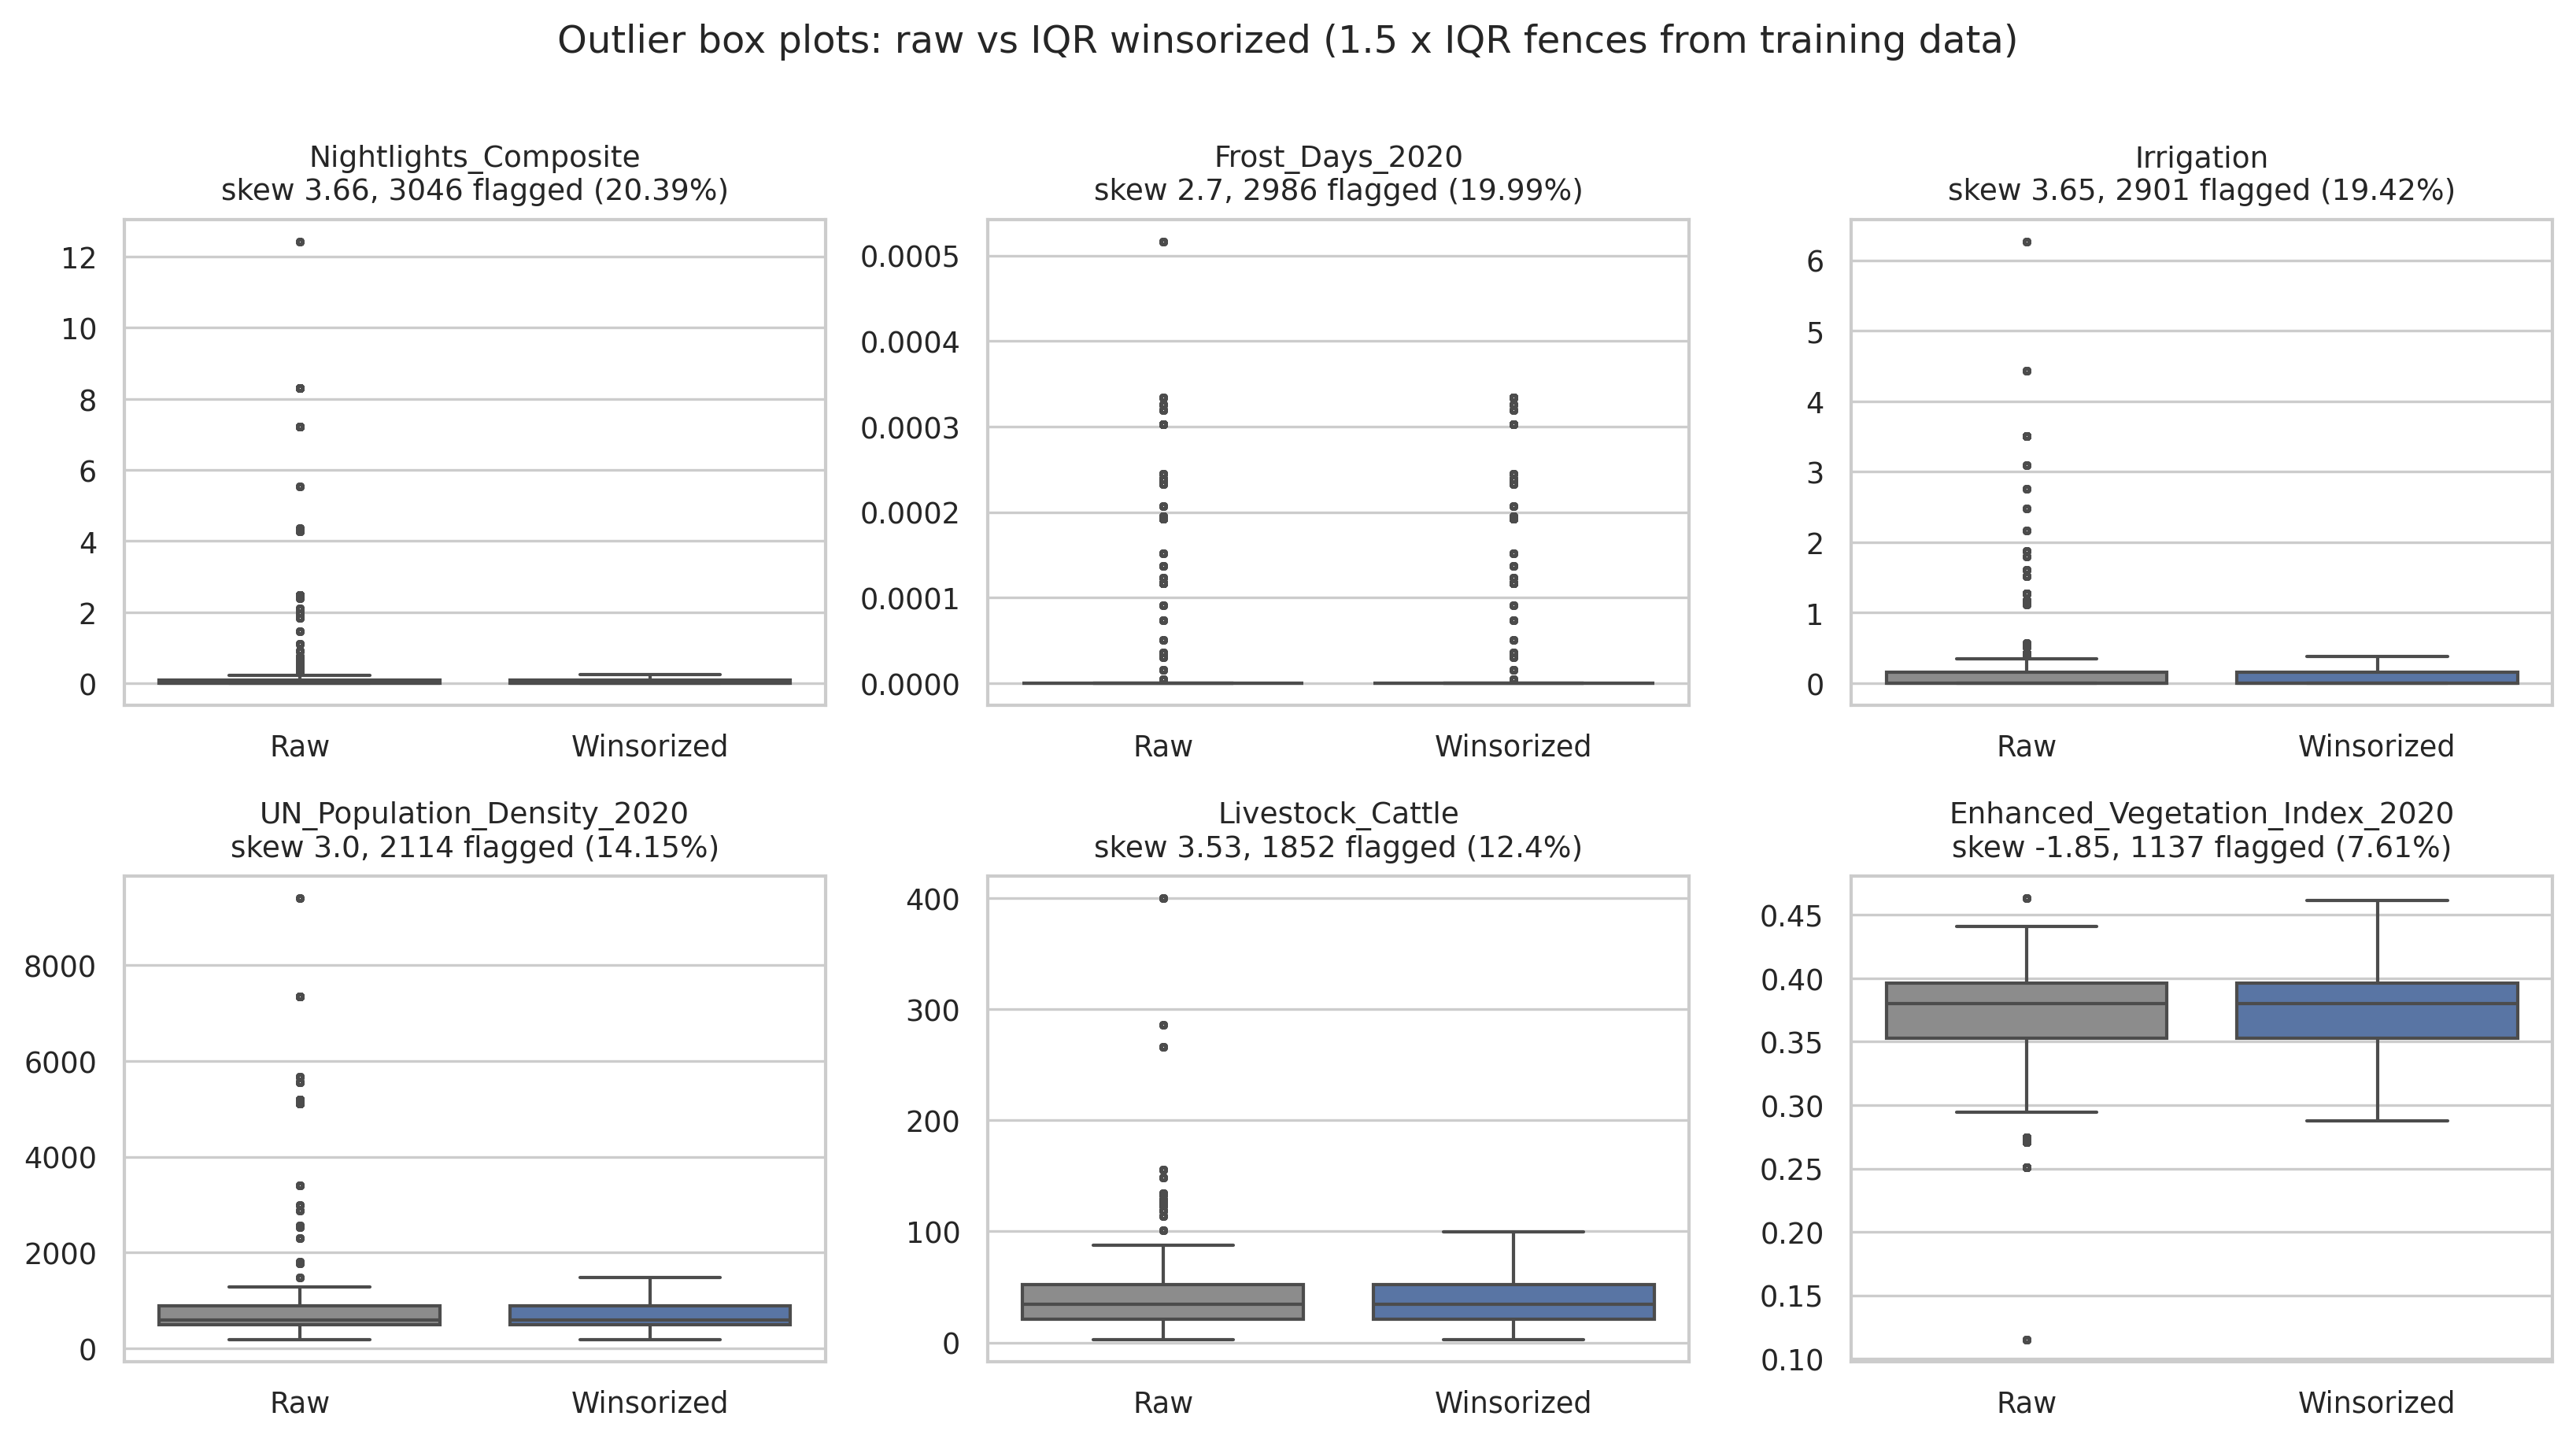

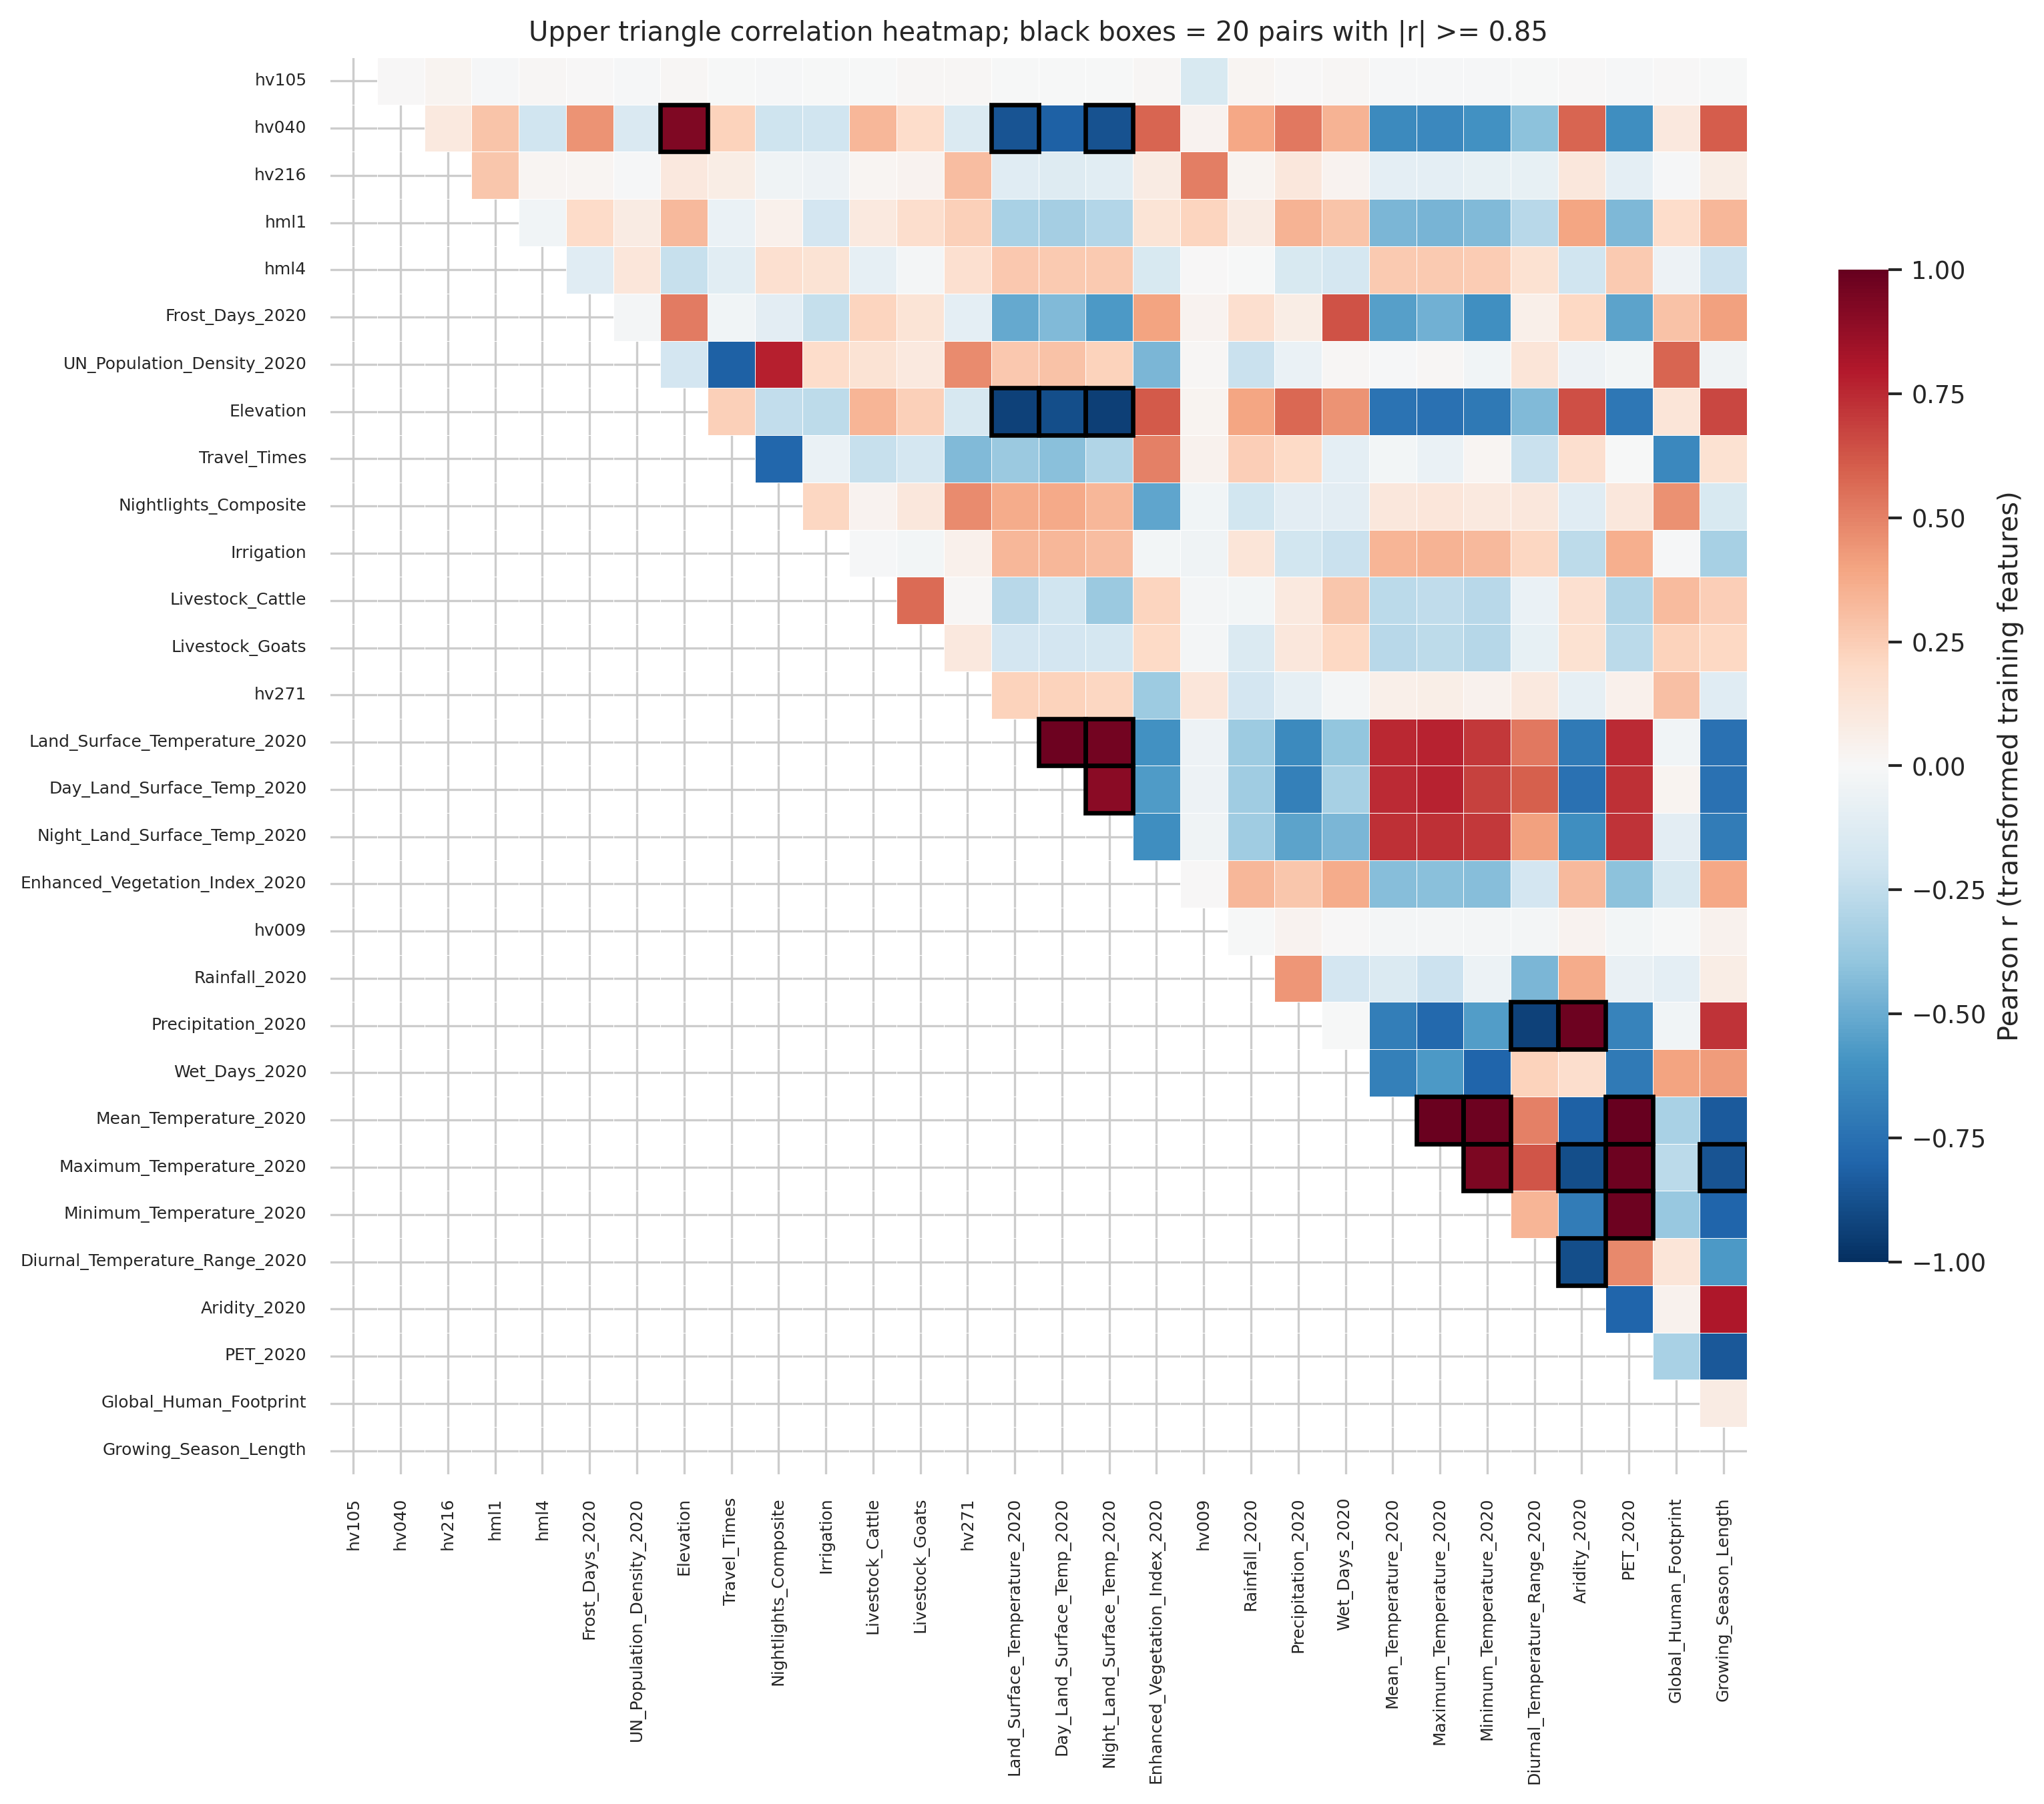

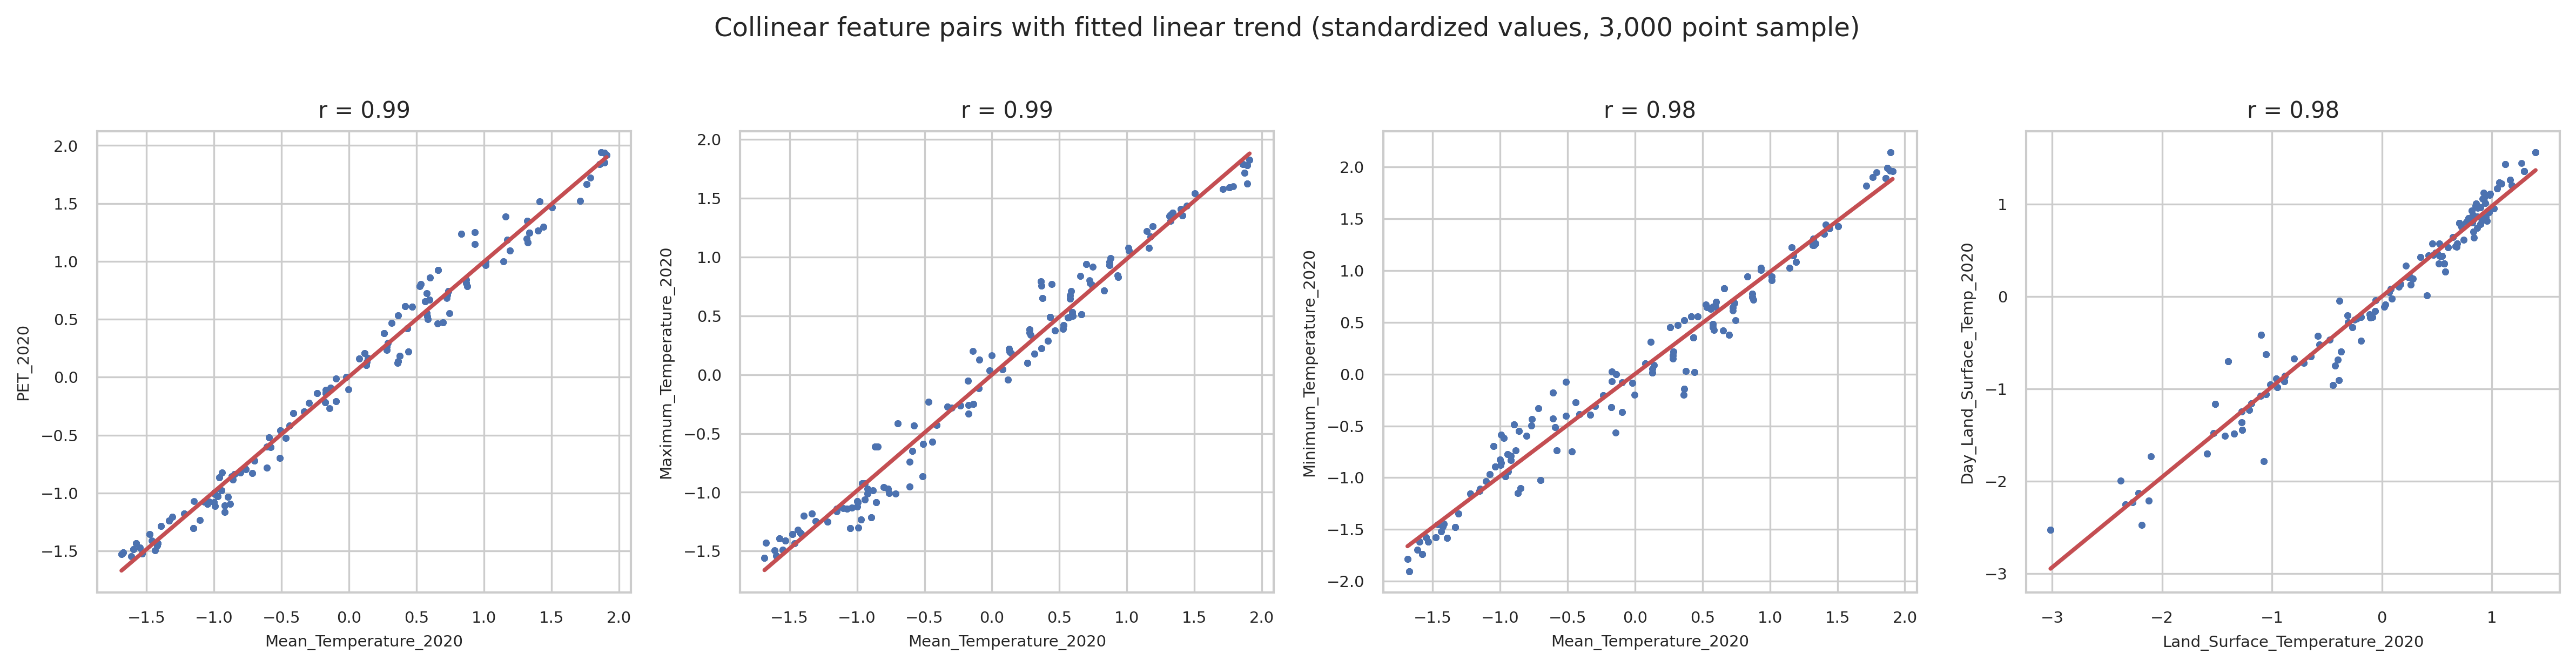

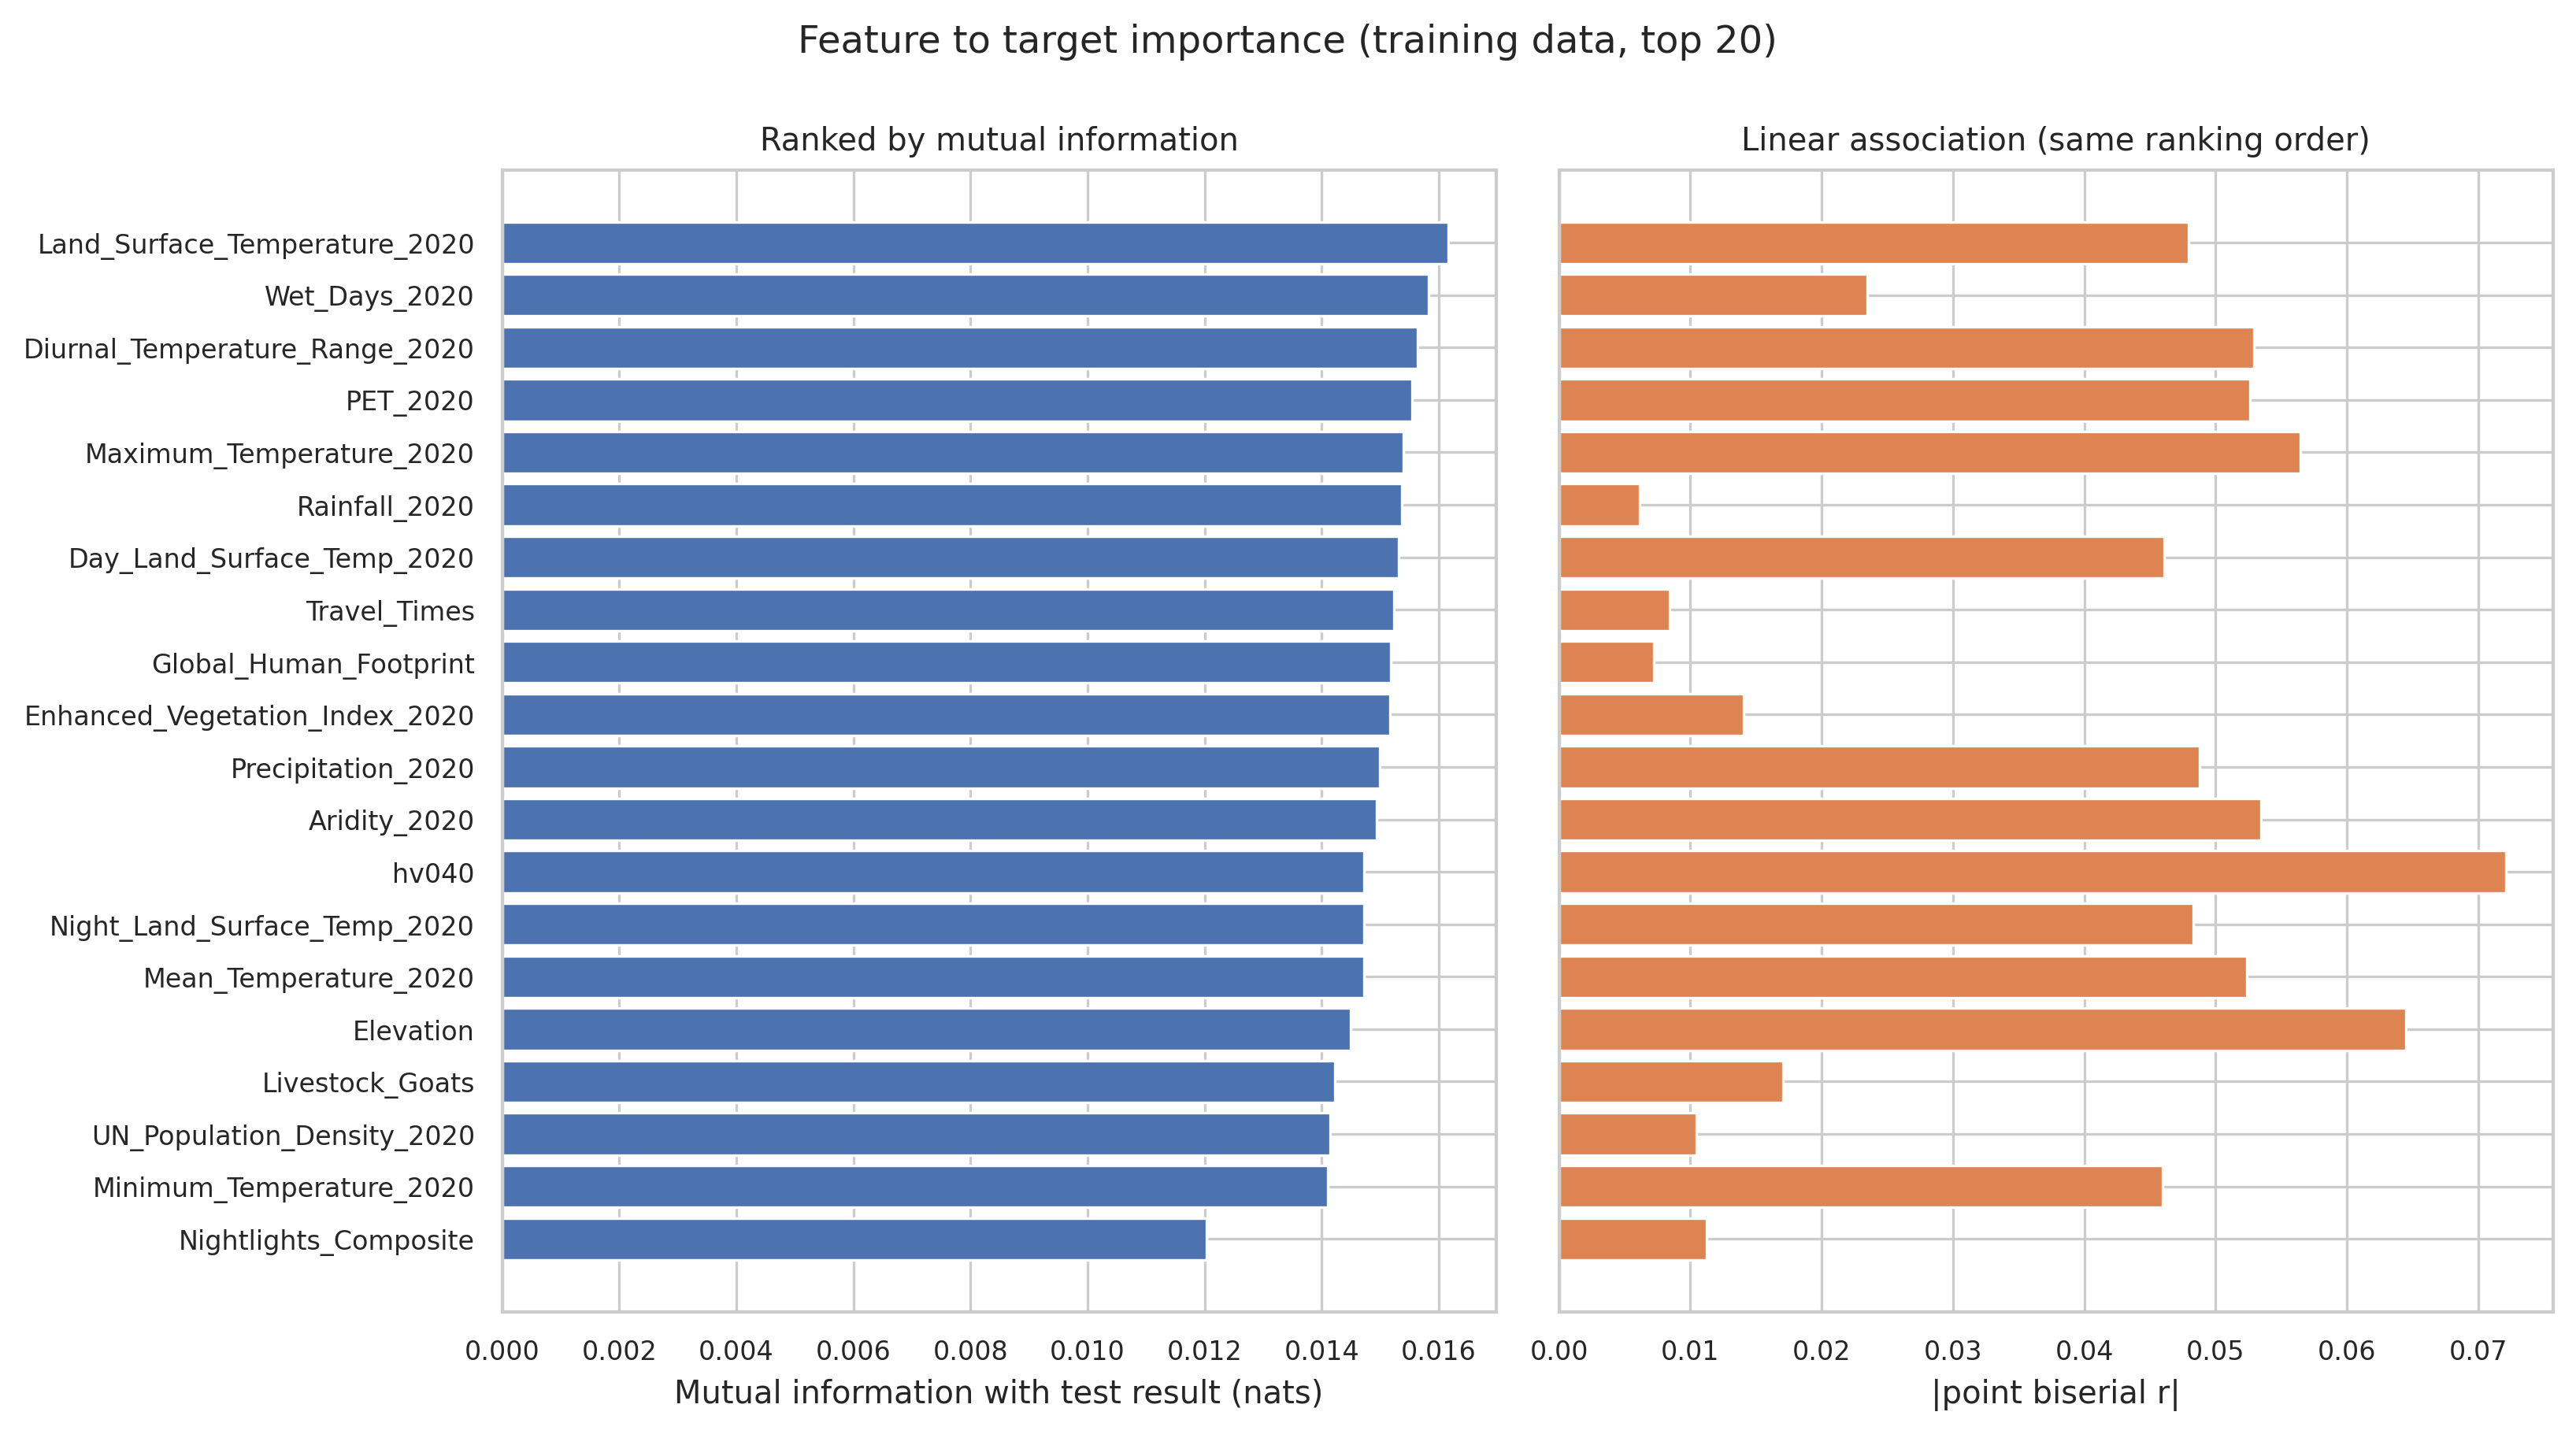

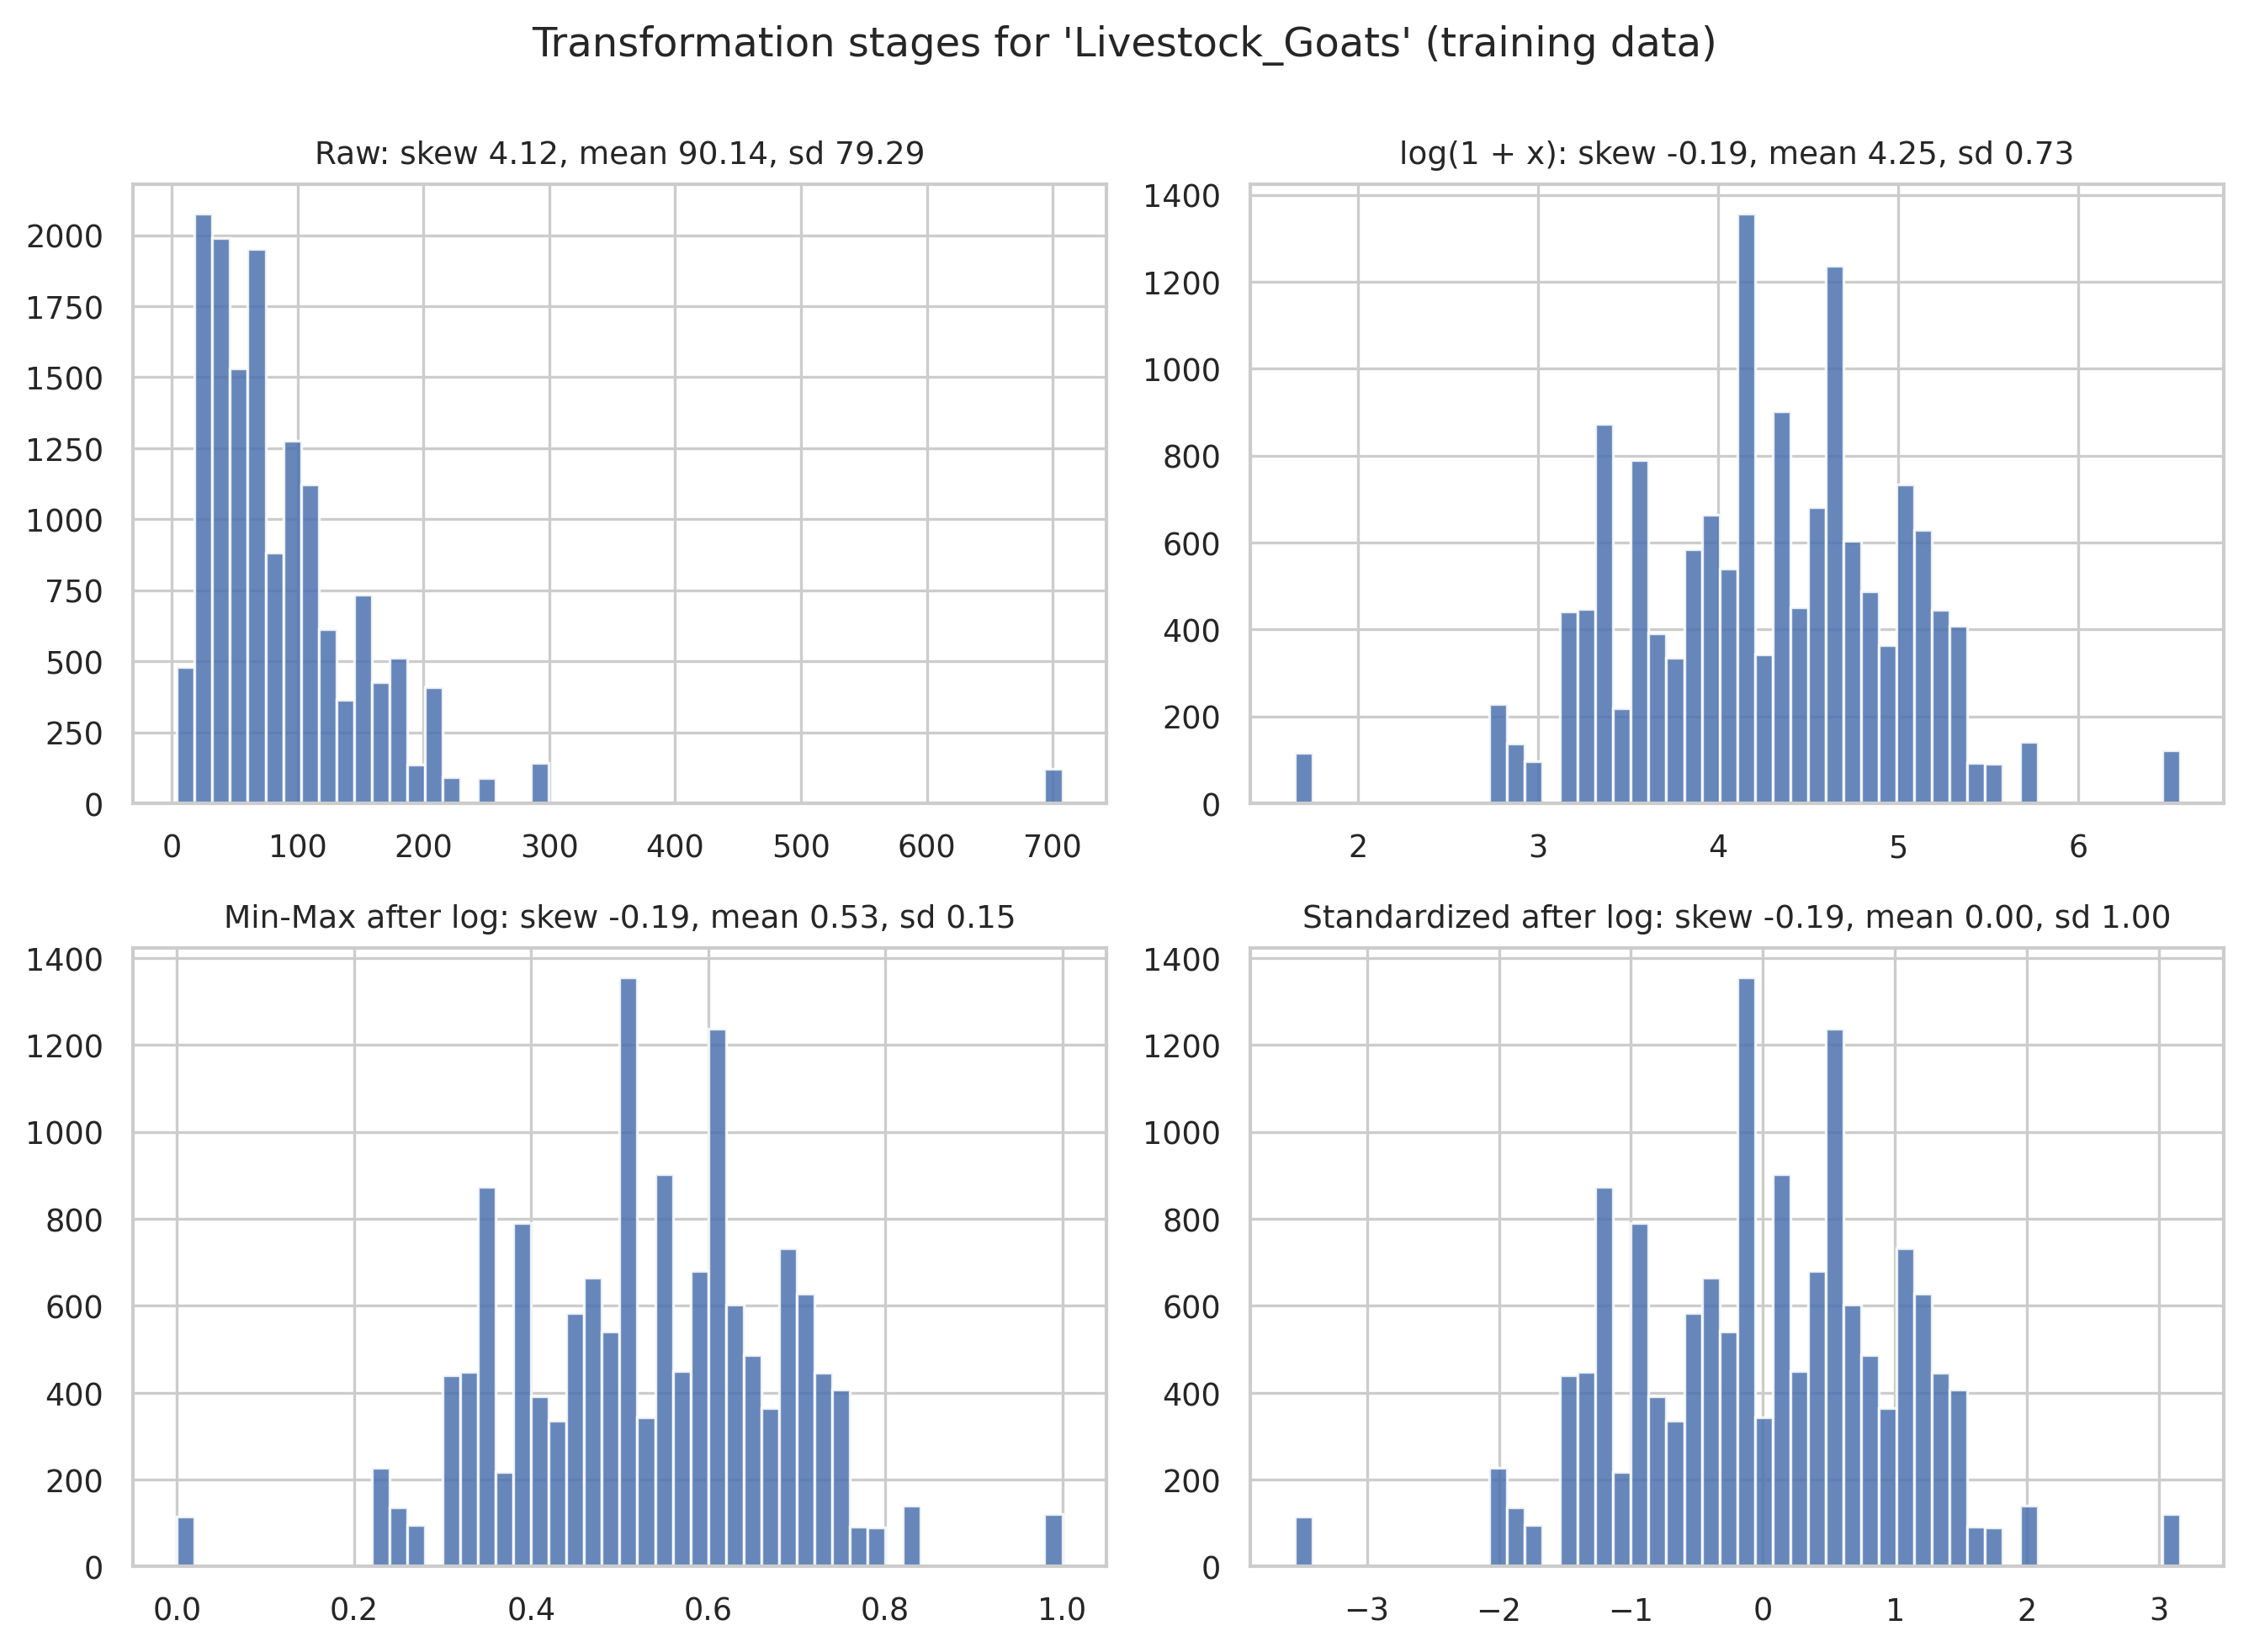

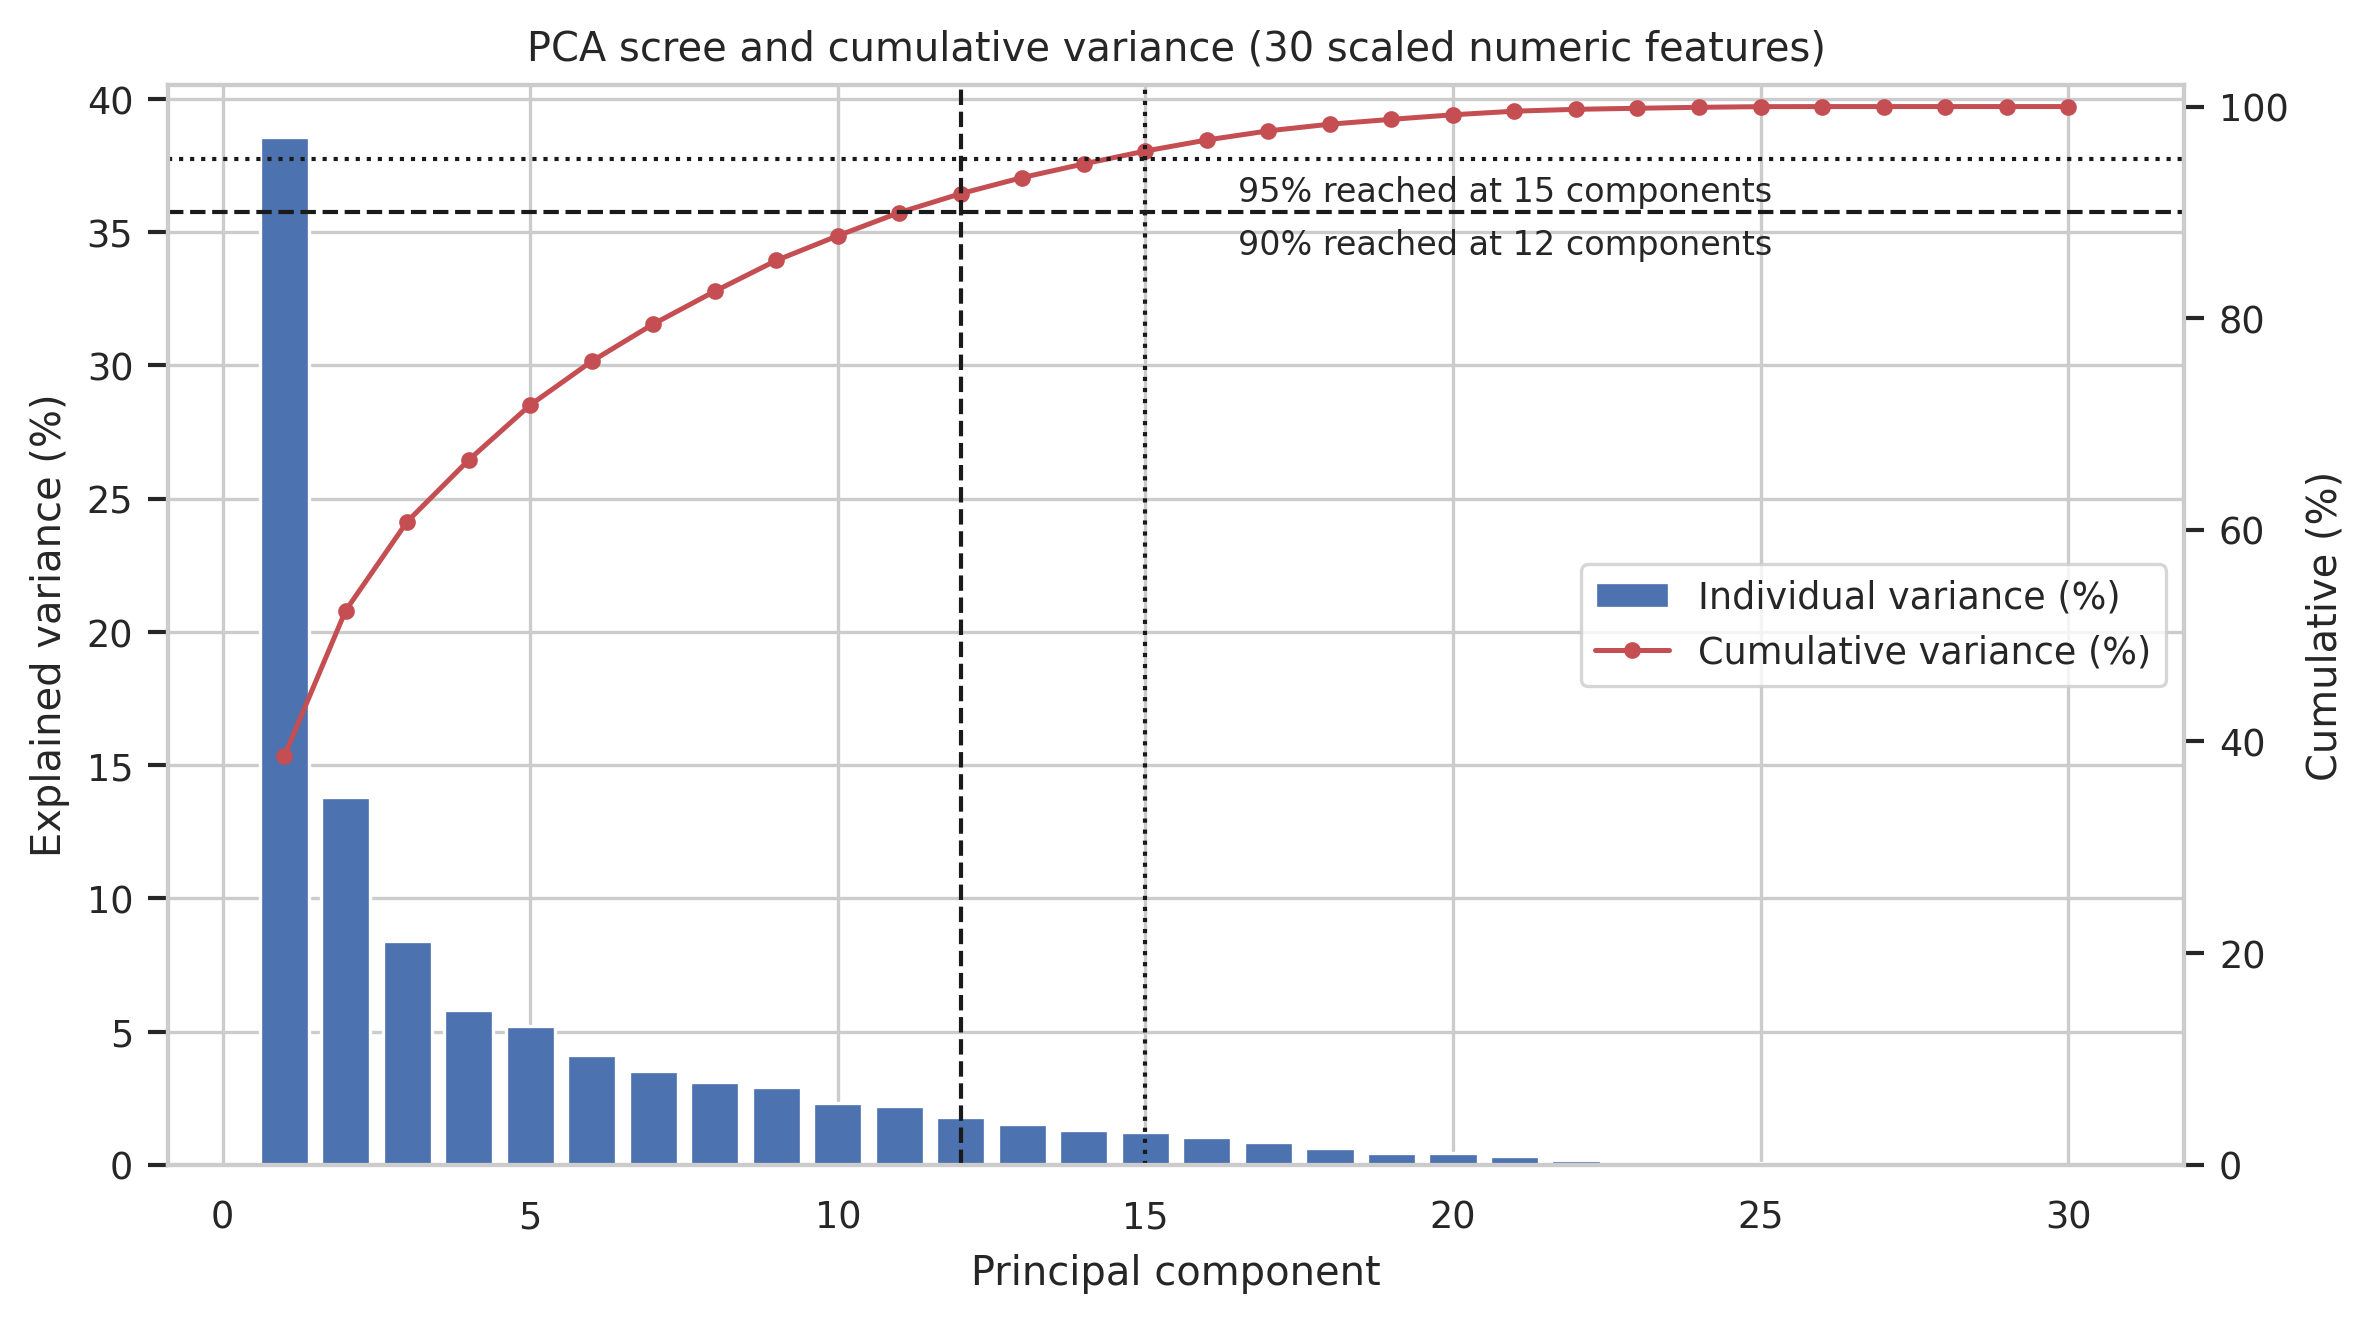

In [6]:
for f in ['fig1_1_missingness_heatmap','fig1_2_target_distribution','fig2_1_outlier_boxplots','fig3_1_correlation_matrix','fig3_2_collinear_scatterplots','fig3_3_target_importance','fig4_1_transformation_grid','fig5_1_pca_scree_plot']:
    display(Image(f'figures/{f}.png', width=800))

## 5. Save processed matrices (git-ignored)

In [7]:
os.makedirs('data/processed', exist_ok=True)
Ztr.assign(y=train.y.values, cluster=train.cluster.values, weight=train.weight.values).to_parquet('data/processed/train.parquet') if False else None
Ztr.to_csv('data/processed/X_train.csv', index=False); Zte.to_csv('data/processed/X_test.csv', index=False)
print('saved')

saved


## 6. Model comparison: grouped out-of-fold CV, calibration, weighted and unweighted metrics

In [8]:
res, preds = run_evaluation(train, test, F, n_boot=200)
rows = []
for m, e in res['models'].items():
    for v in ['raw', 'platt']:
        t = e['test'][v]
        rows.append({'model': m, 'probs': v, 'PR-AUC': t['unweighted']['pr_auc'], 'PR-AUC (w)': t['weighted']['pr_auc'], 'ROC-AUC': t['unweighted']['roc_auc'], 'Brier': t['unweighted']['brier'], 'recall': t['unweighted']['recall'], 'precision': t['unweighted']['precision']})
print('baseline PR-AUC (prevalence):', round(res['baseline_pr_auc'], 4))
display(pd.DataFrame(rows).round(4))

logistic test PR-AUC 0.0132 ROC 0.546


random_forest test PR-AUC 0.0138 ROC 0.625


lightgbm test PR-AUC 0.0156 ROC 0.656


xgboost test PR-AUC 0.0203 ROC 0.643
baseline PR-AUC (prevalence): 0.0096


,model,probs,PR-AUC,PR-AUC (w),ROC-AUC,Brier,recall,precision
0,logistic,raw,0.0132,0.0130,0.5462,0.1573,0.5278,0.0112
1,logistic,platt,0.0132,0.0130,0.5462,0.0096,0.5278,0.0112
2,random_forest,raw,0.0138,0.0129,0.6251,0.0243,0.4722,0.0133
3,random_forest,platt,0.0138,0.0129,0.6251,0.0096,0.4722,0.0133
4,lightgbm,raw,0.0156,0.0150,0.6561,0.0195,0.7500,0.0146
5,lightgbm,platt,0.0156,0.0150,0.6561,0.0097,0.7500,0.0146
6,xgboost,raw,0.0203,0.0193,0.6430,0.0518,0.6389,0.0144
7,xgboost,platt,0.0203,0.0193,0.6430,0.0096,0.6389,0.0144
